# Lab 7 extra help

This notebook is extra help for the Inference Lab. It goes through the same three parts as the lab, but on a practice market that runs instantly, so you can try things out without waiting on `demand`. 

`practice_demand(price)` works just like `demand(price)`: you give it a price, and it gives you back a list of 1s (bought) and 0s (didn't buy), one for each customer. So any code you write here that uses the responses will work in the lab too; just swap in `demand` for `practice_demand`. Code cells marked `# use in the lab` are ones you can copy over. Cells marked `# practice only` run hundreds of market tests or look at the true demand curve, so they only make sense here.

The practice market does **not** have the same demand curve as the lab, so the best price here is not the best price in the lab. Use this to practice the methods, not to find the answer. Section 0 shows you the practice market's true demand curve so you know what you're looking for. In the lab you won't get to see the curve, so after that we'll only use it to check how well our methods worked.

You can run this notebook on your laptop or in Colab.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(5030)

# practice only: the practice market. In the lab, `from demand import demand` replaces everything below.

# practice demand curve
def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

def practice_demand(price):
    """One practice market test. Returns 1s and 0s, one per customer (about 180 customers)."""
    return sales(price, mean_customers=rng.gamma(45.0, 4.0), rng=rng)

## 0. Revenue per customer

If a fraction $p(P)$ of customers buy at price $P$, then the revenue per potential customer is

$$
r(P) = P \times p(P).
$$

If you raise the price, you make more on each sale, but fewer people buy. The best price is the one that balances those two. (If you've had calculus, that's where the slope of $r$ is zero: $r'(P^*) = p(P^*) + P^*\,p'(P^*) = 0$. But you don't need this, and in real life no one gives you $p(P)$ anyway. You have to test prices.)

From one market test, we estimate $p$ with the fraction of customers who bought, $\hat p$, and $r$ with $\hat r = P\,\hat p$.

Here's what the practice market looks like. On the left is the proportion of customers who buy at each price, $p(P)$, and on the right is the revenue per customer, $r(P) = P \times p(P)$. Notice that the revenue curve has more than one peak. The lab's market has a different curve, and you won't get to see it.

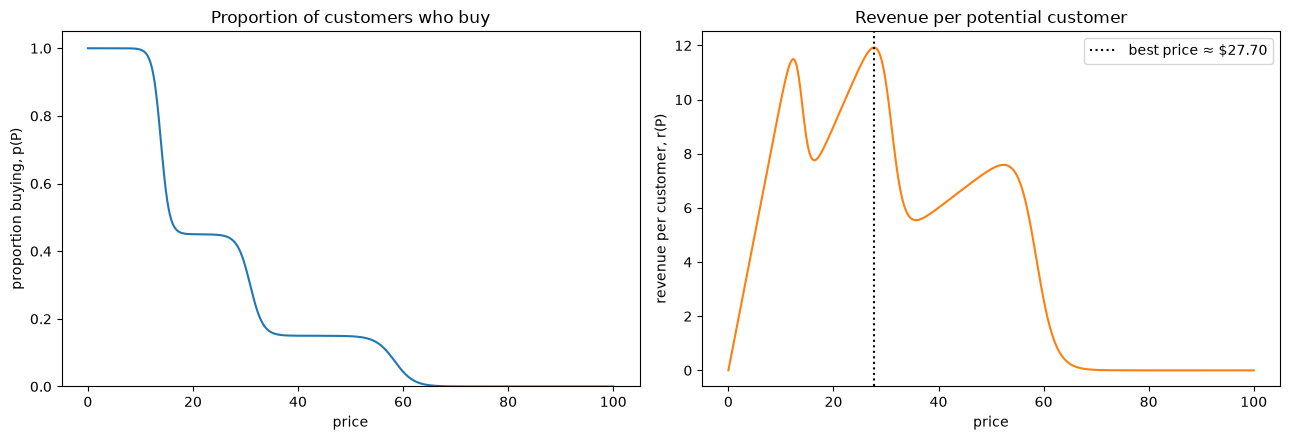

In [3]:
# practice only: the true curve, which you don't get in the lab
prices = np.linspace(0, 100, 1001)
p_true = purchase_probability(prices)
r_true = prices * p_true
best = prices[np.argmax(r_true)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(prices, p_true, color="C0")
axes[0].set(xlabel="price", ylabel="proportion buying, p(P)", title="Proportion of customers who buy", ylim=(0, 1.05))
axes[1].plot(prices, r_true, color="C1")
axes[1].axvline(best, color="black", linestyle=":", label=f"best price ≈ ${best:.2f}")
axes[1].set(xlabel="price", ylabel="revenue per customer, r(P)", title="Revenue per potential customer")
axes[1].legend()
plt.tight_layout()
plt.show()

In [4]:
# use in the lab
responses = practice_demand(14.0)
n = len(responses)
p_hat = responses.mean()
print(f"{n} customers, {responses.sum()} bought: p_hat = {p_hat:.3f}, r_hat = 14 * p_hat = {14.0 * p_hat:.2f}")

180 customers, 132 bought: p_hat = 0.733, r_hat = 14 * p_hat = 10.27


### Same price, different revenue

Here we run 100 market tests at \$20 and 100 at \$25 and plot $\hat r$ for each. That's 200 market tests, which takes a few seconds here and over an hour in the lab, so this is something you can only do on the practice market.

The two distributions overlap a lot. If you only run one test at each price, you could easily get the order wrong. That's why we need standard errors and confidence intervals.

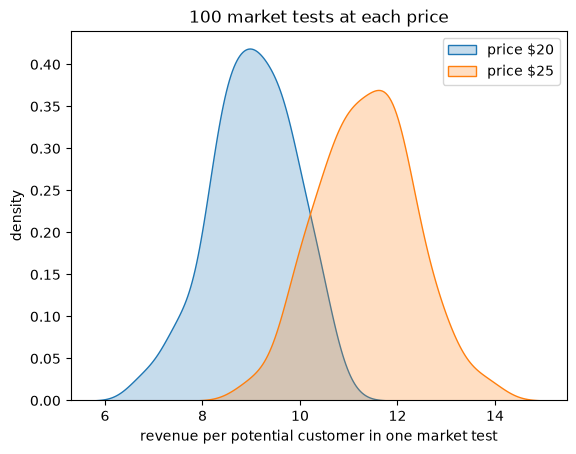

In [5]:
# practice only: 200 market tests
repeats = 100
r_hat_20 = [20 * practice_demand(20).mean() for _ in range(repeats)]
r_hat_25 = [25 * practice_demand(25).mean() for _ in range(repeats)]

sns.kdeplot(r_hat_20, fill=True, label=r"price \$20")
sns.kdeplot(r_hat_25, fill=True, label=r"price \$25")
plt.xlabel("revenue per potential customer in one market test")
plt.ylabel("density")
plt.title("100 market tests at each price")
plt.legend()
plt.show()

## 1. Compare two prices (lab Part 1)

In the lab you compare \$25 and \$30. Here we'll compare \$20 and \$25, with one market test each, and go through the same steps.

In [6]:
# use in the lab (with demand, and prices 25 and 30)
price_A, price_B = 20.0, 25.0
resp_A = practice_demand(price_A)
resp_B = practice_demand(price_B)

# p_hat and r_hat at each price
for P, resp in [(price_A, resp_A), (price_B, resp_B)]:
    print(f"${P:g}: n = {len(resp)}, p_hat = {resp.mean():.3f}, r_hat = {P * resp.mean():.2f}")

$20: n = 193, p_hat = 0.363, r_hat = 7.25
$25: n = 216, p_hat = 0.431, r_hat = 10.76


### Standard error of $\hat r$

The lab asks you to bootstrap this. Resample the customers you saw, with replacement, and recompute $\hat r$. Do that $B$ times. The standard deviation of those $B$ values of $\hat r$ is your bootstrap SE.

You can also check it with a formula. $\hat r$ is just $P$ times the mean of a bunch of 0s and 1s. A 0/1 variable has standard deviation $\sqrt{p(1-p)}$, and the SE of a mean divides that by $\sqrt n$, so

$$
\text{SE}(\hat r) = P\,\sqrt{\frac{\hat p(1-\hat p)}{n}}.
$$

The two should be pretty close.

In [7]:
# use in the lab
B = 2000

def bootstrap_r(responses, price, B=B):
    """B bootstrap values of r_hat."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """SE of r_hat from P * sqrt(p_hat (1 - p_hat) / n)."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": price_A, "r_hat": price_A * resp_A.mean(),
     "SE (bootstrap)": reps_A.std(ddof=1), "SE (formula)": se_formula(resp_A, price_A)},
    {"price": price_B, "r_hat": price_B * resp_B.mean(),
     "SE (bootstrap)": reps_B.std(ddof=1), "SE (formula)": se_formula(resp_B, price_B)},
]).round(3)

,price,r_hat,SE (bootstrap),SE (formula)
0,20.0,7.254,0.705,0.692
1,25.0,10.764,0.815,0.842


### 95% confidence interval for each price

From the bootstrap, take the 2.5th and 97.5th percentiles of the bootstrap values. Or use the normal approximation, $\hat r \pm 1.96 \times \text{SE}$ (the CLT says $\hat r$ is approximately normal). Again, these should be close.

In [8]:
# use in the lab
def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])

,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,20.0,193,7.25,"(5.91, 8.60)","(5.90, 8.61)"
1,25.0,216,10.76,"(9.03, 12.27)","(9.11, 12.41)"


### 95% confidence interval for the difference

To decide which price is better, don't just look at whether the two intervals above overlap. Make a confidence interval for the difference $r_{20} - r_{25}$.

With the bootstrap, the two samples are independent, so you can subtract the bootstrap values for one price from the bootstrap values for the other, and take the 2.5th and 97.5th percentiles of the differences.

With the formula: when you subtract two independent estimates, their variances add, so

$$
\text{SE}(\hat r_A - \hat r_B) = \sqrt{\text{SE}_A^2 + \text{SE}_B^2},
$$

and the interval is $(\hat r_A - \hat r_B) \pm 1.96 \times \text{SE}(\hat r_A - \hat r_B)$.

In [9]:
# use in the lab
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    """95% CI for r_A - r_B, from the bootstrap and from the formula."""
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B)
print(f"r_20 - r_25 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$20', '$25')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$20', '$25')}")

r_20 - r_25 = -3.51
  95% CI, bootstrap: (-5.58, -1.25)  ->  $25 earns more
  95% CI, formula:   (-5.65, -1.37)  ->  $25 earns more


### Interpreting it

If the whole interval is below 0, that's evidence \$25 earns more than \$20. If it's all above 0, that's evidence \$20 earns more. If the interval includes 0, you can't tell which is better from this data. That does **not** mean the two prices earn the same! It might just mean you didn't collect enough data to see the difference. The next section looks at how often that happens.

## 2. The cost of sampling (lab Part 2)

### Pooling a second test

Run another test at each price and combine it with the first one using `np.concatenate`. Now you have about twice as many customers. Since $n$ is under a square root in the SE formula, the SE should shrink by about $1/\sqrt 2 \approx 0.71$.

In [10]:
# use in the lab
pool_A = np.concatenate([resp_A, practice_demand(price_A)])
pool_B = np.concatenate([resp_B, practice_demand(price_B)])
pool_reps_A = bootstrap_r(pool_A, price_A)
pool_reps_B = bootstrap_r(pool_B, price_B)

print(f"SE ratio (pooled / one test), bootstrap: ${price_A:g}: {pool_reps_A.std(ddof=1) / reps_A.std(ddof=1):.2f}, "
      f"${price_B:g}: {pool_reps_B.std(ddof=1) / reps_B.std(ddof=1):.2f};  1/sqrt(2) = {1 / np.sqrt(2):.2f}")

d, boot, z = diff_ci(pool_A, price_A, pool_reps_A, pool_B, price_B, pool_reps_B)
print(f"pooled r_20 - r_25 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$20', '$25')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$20', '$25')}")

SE ratio (pooled / one test), bootstrap: $20: 0.70, $25: 0.79;  1/sqrt(2) = 0.71
pooled r_20 - r_25 = -2.24
  95% CI, bootstrap: (-3.79, -0.60)  ->  $25 earns more
  95% CI, formula:   (-3.85, -0.63)  ->  $25 earns more


### How often does one test settle it?

In the lab, you only get to run your comparison once. On the practice market we can run it over and over and see how often the interval for $r_{20} - r_{25}$ actually excludes 0.

Each "experiment" below pools $k$ market tests at each price and computes a 95% interval for the difference. (We use the formula here because it's faster; you saw above that it's close to the bootstrap.) The left plot is 100 experiments with 1 test per price, and the right is 100 experiments with 4 tests per price. Red intervals exclude 0. The green line is the true difference, which we only know because this is the practice market.

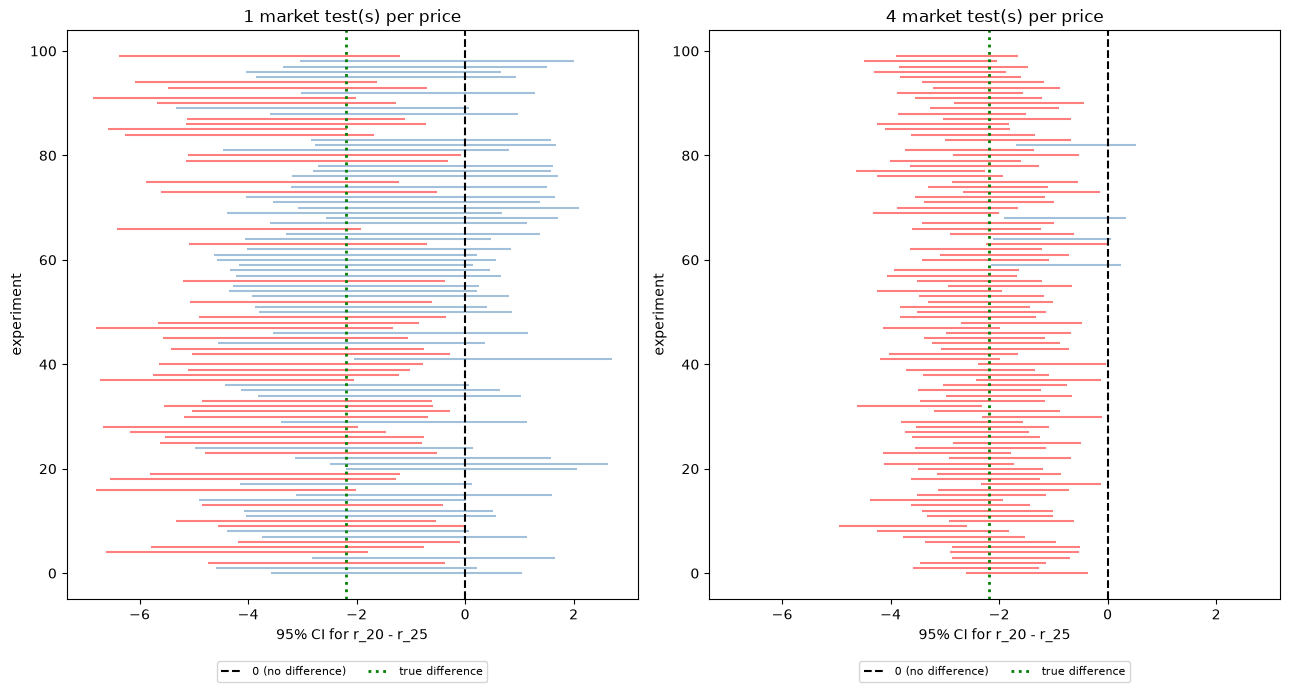

In [11]:
# practice only: hundreds of market tests, and uses the true curve
def one_experiment(k):
    """Pool k market tests at each price and return the 95% CI for r_A - r_B."""
    a = np.concatenate([practice_demand(price_A) for _ in range(k)])
    b = np.concatenate([practice_demand(price_B) for _ in range(k)])
    d = price_A * a.mean() - price_B * b.mean()
    se = np.sqrt(se_formula(a, price_A) ** 2 + se_formula(b, price_B) ** 2)
    return d - 1.96 * se, d + 1.96 * se

true_diff = price_A * purchase_probability(price_A) - price_B * purchase_probability(price_B)

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharex=True)
for ax, k in zip(axes, [1, 4]):
    CIs = np.array([one_experiment(k) for _ in range(100)])
    for i, (lo, hi) in enumerate(CIs):
        ax.hlines(i, lo, hi, color="steelblue" if lo <= 0 <= hi else "red", alpha=0.5, linewidth=1.5)
    ax.axvline(0, color="black", linestyle="--", label="0 (no difference)")
    ax.axvline(true_diff, color="green", linestyle=":", linewidth=2, label="true difference")
    ax.set(title=f"{k} market test(s) per price", xlabel="95% CI for r_20 - r_25", ylabel="experiment")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

**Power** is the fraction of experiments whose interval excludes 0, i.e. how often the experiment actually tells you which price is better. **Coverage** is the fraction of intervals that contain the true difference. For a 95% interval, coverage should be about 95% no matter how much data you have. (We can only check coverage because we know the true difference here.)

$$
\widehat{\text{Power}} = \frac{\text{number of intervals that exclude } 0}{\text{number of experiments}},
\qquad
\widehat{\text{Coverage}} = \frac{\text{number of intervals that contain the true difference}}{\text{number of experiments}}
$$

In [12]:
# practice only: thousands of market tests, and uses the true curve
rows = []
for k in [1, 2, 4, 8]:
    CIs = np.array([one_experiment(k) for _ in range(1000)])
    rows.append({
        "market tests per price": k,
        "total tests": 2 * k,
        "power": np.mean((CIs[:, 0] > 0) | (CIs[:, 1] < 0)),
        "coverage": np.mean((CIs[:, 0] <= true_diff) & (true_diff <= CIs[:, 1])),
        "average CI width": np.mean(CIs[:, 1] - CIs[:, 0]),
    })
print(f"true r_20 - r_25: {true_diff:.2f}")
pd.DataFrame(rows).round(3)

true r_20 - r_25: -2.19


,market tests per price,total tests,power,coverage,average CI width
0,1,2,0.466,0.944,4.714
1,2,4,0.726,0.943,3.300
2,4,8,0.948,0.931,2.334
3,8,16,1.000,0.950,1.647


Coverage stays around 95% the whole time (sometimes a little under, since the normal approximation isn't perfect). More data doesn't make the interval more "correct," it makes it narrower.

Power goes up a lot with more data. With one test at each price, the interval only excludes 0 less than half the time, even though \$25 really does earn about \$2.19 more per customer than \$20. So "can't tell" is actually the most likely result after one round!

The width of the interval shrinks like $1/\sqrt{k}$: four times as many tests gets you an interval half as wide. That's expensive. And every test is time you aren't selling at your best price, which is exactly what Part 2, Question 9 is asking you to think about.

## 3. Finding the best price (lab Part 3)

In the lab you want to use fewer than 25 market tests, so don't throw any data away. If you test the same price twice, pool the results. You'll also need to keep count of your tests for the write-up. `run_test` below does both: it saves every test in a dictionary, and returns all the responses so far at that price. You pass it the market function, so it's `run_test(practice_demand, ...)` here and `run_test(demand, ...)` in the lab.

The lab hints mention two ways to search. You can scan a bunch of prices across the range, or you can hill climb: compare two nearby prices and move toward the better one. A scan wastes tests on prices that are obviously bad. Hill climbing only finds the top of whatever hill you start on.

In [13]:
# use in the lab: run_test(demand, price, data)
data = {}   # price -> list of response arrays, one per market test

def run_test(market, price, data):
    """Run one market test at price, save it, and return all responses at that price so far."""
    data.setdefault(price, []).append(market(price))
    return np.concatenate(data[price])

def tests_run(data):
    """Total number of market tests saved in data."""
    return sum(len(tests) for tests in data.values())

### A coarse scan

Here's one market test every \$10 from \$10 to \$100, with error bars of $\hat r \pm 1.96\,\text{SE}$. The dashed line is the true $r(P)$ for the practice market. You won't have that line in the lab, so delete that line of code if you copy this over.

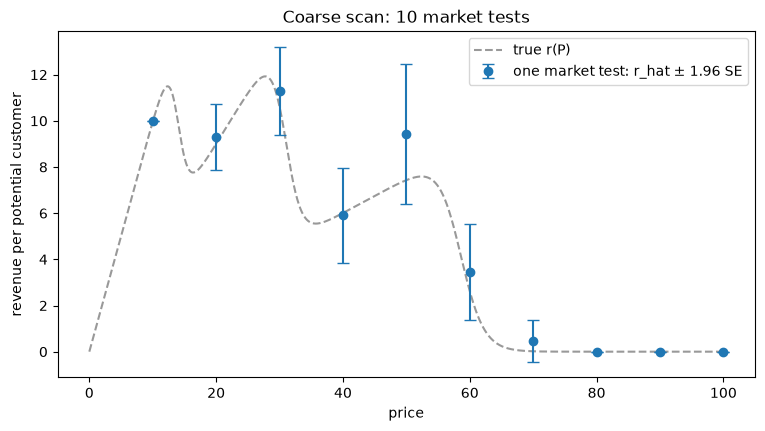

In [14]:
# use in the lab (except the true-curve line)
scan_prices = np.arange(10, 101, 10.0)
scan = {P: run_test(practice_demand, P, data) for P in scan_prices}

r_hats = np.array([P * scan[P].mean() for P in scan_prices])
ses = np.array([se_formula(scan[P], P) for P in scan_prices])

grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.plot(grid, grid * purchase_probability(grid), "k--", alpha=0.4, label="true r(P)")  # practice only: delete in the lab
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o", capsize=4, label="one market test: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

Pretend the dashed line isn't there and just look at the error bars. Prices whose intervals are well below the best one probably aren't worth testing again. Prices you can't tell apart from the best one are where you should spend more tests. Also notice that a \$10 grid can jump right over a narrow peak, so a scan tells you where to look, not the final answer.

In the lab, a 10-test scan would use up 40% of a 25-test budget, so think about how many scan points you can actually afford.

### Comparing neighbors

Hill climbing is just the Part 1 comparison done at two nearby prices, $P - h$ and $P + h$. If the interval for $r(P+h) - r(P-h)$ is all above 0, raise the price. If it's all below 0, lower it. If it includes 0, you can't tell yet: either test both prices again to narrow the interval, or compare prices that are farther apart so the difference is bigger.

(If you divide the difference by $2h$, you get an estimate of the slope of $r$ at $P$. The ds4e notebook calls this the gradient.)

In [15]:
# use in the lab: compare_neighbors(demand, price, h, data)
def compare_neighbors(market, price, h, data):
    """Test price - h and price + h once more each (pooled with earlier tests),
    and return the 95% CI for r(price + h) - r(price - h)."""
    lo_p, hi_p = price - h, price + h
    low, high = run_test(market, lo_p, data), run_test(market, hi_p, data)
    d = hi_p * high.mean() - lo_p * low.mean()
    se = np.sqrt(se_formula(low, lo_p) ** 2 + se_formula(high, hi_p) ** 2)
    ci = (d - 1.96 * se, d + 1.96 * se)
    move = "raise" if ci[0] > 0 else ("lower" if ci[1] < 0 else "can't tell")
    return {"price": price, "compared": f"${lo_p:g} vs ${hi_p:g}", "difference": d,
            "ci_low": ci[0], "ci_high": ci[1], "slope": d / (2 * h), "move": move}

comparisons = pd.DataFrame([compare_neighbors(practice_demand, P, 5.0, data) for P in [20.0, 35.0, 45.0, 55.0]])
print(f"market tests so far: {tests_run(data)}")
comparisons.round(2)

market tests so far: 18


,price,compared,difference,ci_low,ci_high,slope,move
0,20.0,$15 vs $25,1.82,-0.41,4.04,0.18,can't tell
1,35.0,$30 vs $40,-6.46,-8.55,-4.37,-0.65,lower
2,45.0,$40 vs $50,2.28,-0.03,4.60,0.23,can't tell
3,55.0,$50 vs $60,-4.11,-6.31,-1.91,-0.41,lower


Some of these prices (\$30, \$40, \$50, \$60) were already in the scan, and \$40 and \$50 each show up in two comparisons. Because `run_test` pools everything, those comparisons use two or three tests at those prices instead of one.

Look at \$45 and \$55. At \$45 the interval often includes 0, because the true revenues at \$40 and \$50 are only about \$1.40 apart, which is hard to detect with this much data. At \$55 it says to lower the price. So there's a peak somewhere between \$45 and \$55. That peak is real, but it's not the highest one, and if you started hill climbing around \$45 you'd get stuck there.

### What hill climbing costs without a budget

You could use gradient ascent: estimate the slope from two nearby prices (300 customers each), move the price in that direction, and repeat 80 times, taking smaller steps as it goes. Here it is from three starting prices. Since `demand` doesn't let you choose the number of customers, this uses the underlying `sales()` function. To compare with the lab, we convert the number of customers it used into lab market tests (about 180 customers each). **YOU ARE NOT EXPECTED TO DO GRADIENT ASCENT.** This is a nice example of what you would try if you had a lot of time to do market tests and could take small steps as you get close to the true optimal price. The below code is an example of what this would look like. Again, I am not expecting you to do this for your lab. But you can use the idea of gradient ascent as you form your strategy for the lab.

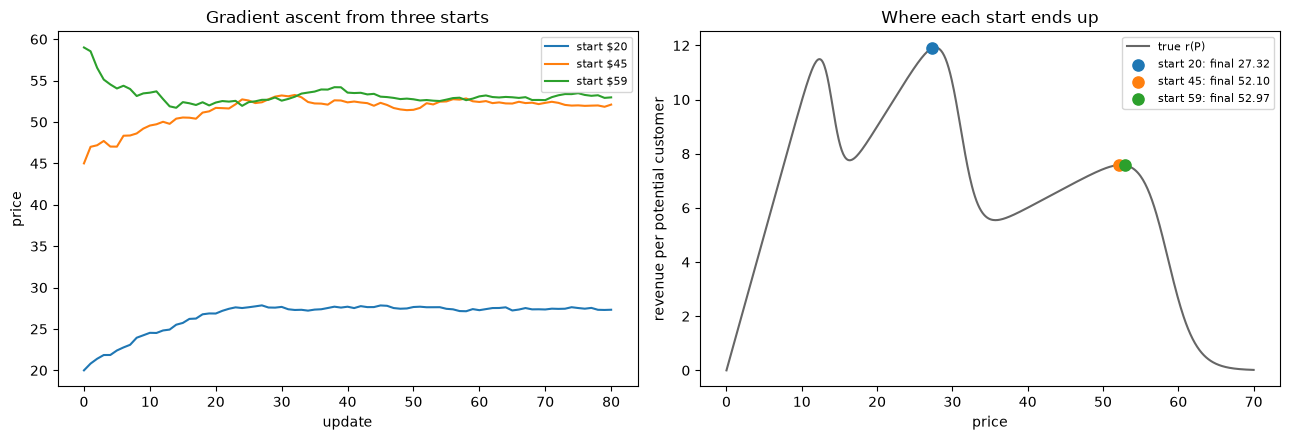

,start,final price,customers used,≈ lab market tests,share of best revenue
0,20.0,27.32,48255,268.08,1.00
1,45.0,52.10,47895,266.08,0.64
2,59.0,52.97,47770,265.39,0.64


In [16]:
# practice only: about 265 market tests' worth of customers per run, and uses the true curve
def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low, price_high = max(0, price - step), min(75, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    gap = price_high - price_low
    return {"price": price, "gradient": (high.mean() - low.mean()) / gap,
            "customers": len(low) + len(high)}

def gradient_ascent(start_price, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step, mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

starts = [20.0, 45.0, 59.0]
paths = {s: gradient_ascent(s, seed=2026 + int(s)) for s in starts}

grid = np.linspace(0, 70, 701)
best_r = (grid * purchase_probability(grid)).max()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[1].plot(grid, grid * purchase_probability(grid), color="black", alpha=0.6, label="true r(P)")
summary = []
for i, (s, hist) in enumerate(paths.items()):
    prices = np.r_[s, hist["next_price"].to_numpy()]
    final = prices[-1]
    axes[0].plot(prices, color=f"C{i}", label=f"start ${s:g}")
    axes[1].scatter(final, final * purchase_probability(final), color=f"C{i}", s=65, zorder=3,
                    label=f"start {s:g}: final {final:.2f}")
    customers = int(hist["customers"].sum())
    summary.append({"start": s, "final price": final, "customers used": customers,
                    "≈ lab market tests": customers / 180,
                    "share of best revenue": float(final * purchase_probability(final) / best_r)})
axes[0].set(xlabel="update", ylabel="price", title="Gradient ascent from three starts")
axes[1].set(xlabel="price", ylabel="revenue per potential customer", title="Where each start ends up")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame(summary).round(2)

The runs that start at \$45 and \$59 both get stuck on the lower peak near \$52. That's why Hint 2 in the lab suggests trying a few prices across the range before you start climbing.

Also look at the cost: each run uses about 265 lab market tests' worth of customers, which is more than ten times the lab budget. It also moves every step, even when the slope it estimated could just be noise. In the lab you can't afford that. Only move when your interval says to, test again when it can't tell, and take smaller steps as you get close.

## Things to think about before the lab

- How much data do you want at a price before you make a decision?
- What's the smallest change in price worth testing? Near the peak, nearby prices earn almost the same, and you won't be able to tell them apart without a lot of tests.
- If an interval includes 0, is it better to test the same prices again or to compare prices farther apart?
- How many tests will you spend scanning vs. hill climbing?
- When will you stop?

### Using this code in the lab

Copy the `# use in the lab` cells into your lab notebook after `from demand import demand`, and use `demand` wherever this notebook uses `practice_demand`. For example:

```python
from demand import demand

data = {}
resp_25 = run_test(demand, 25.0, data)
resp_30 = run_test(demand, 30.0, data)
d, boot, z = diff_ci(resp_25, 25.0, bootstrap_r(resp_25, 25.0),
                     resp_30, 30.0, bootstrap_r(resp_30, 30.0))
print(f"r_25 - r_30 = {d:.2f}, 95% bootstrap CI ({boot[0]:.2f}, {boot[1]:.2f})")
print(f"market tests so far: {tests_run(data)}")
```

Don't copy the `# practice only` cells. They'd run hundreds of slow market tests, and they use `purchase_probability`, which you don't have in the lab.